# 01 - Stress on the foliation plane

In a triaxial test the specimen has the axial stress `sigma1 = sigma3 + D` and the confining stress `sigma3`.
`D` is the deviator (the load beyond the confinement). The plane has dip `theta`, measured from the horizontal.
We need the normal stress `sn` and the shear stress `tau` on that plane.

**Where the formulas come from (Mohr's circle).** The plane normal makes the angle `theta` with the specimen axis.
Resolving the two principal stresses on the plane gives

- `sn = sigma1 cos^2(theta) + sigma3 sin^2(theta)`, which becomes `sigma3 + D cos^2(theta)`
- `tau = (sigma1 - sigma3) sin(theta) cos(theta)`, which becomes `D sin(theta) cos(theta)`

The plane slides when `tau` reaches the Coulomb strength `c + sn tan(phi)`. Put the two expressions in this condition and
solve for `D`: this is the peak deviator that the plane can carry (Jaeger).

In [1]:
import numpy as np, matplotlib.pyplot as plt

def sn_tau(s3, D, dip_deg):
    th = np.radians(dip_deg)
    return s3 + D*np.cos(th)**2, D*np.sin(th)*np.cos(th)

def jaeger_D(s3, dip_deg, c, phi_deg):
    th = np.radians(dip_deg); t = np.tan(np.radians(phi_deg))
    den = np.sin(th)*np.cos(th) - np.cos(th)**2*t
    return np.where(den > 0, (c + s3*t)/den, np.inf)   # inf: the plane cannot slide at this dip

# one example
s3, dip, c, phi = 12.0, 40.0, 10.0, 22.0
D = float(jaeger_D(s3, dip, c, phi))
sn, tau = sn_tau(s3, D, dip)
print(f"peak deviator D = {D:.1f} MPa;  sn = {sn:.1f} MPa;  tau = {tau:.1f} MPa")
print(f"Coulomb strength at this sn: c + sn tan(phi) = {c + sn*np.tan(np.radians(phi)):.1f} MPa  (equals tau)")

peak deviator D = 58.2 MPa;  sn = 46.1 MPa;  tau = 28.6 MPa
Coulomb strength at this sn: c + sn tan(phi) = 28.6 MPa  (equals tau)


The last line checks the result: at the peak of the plane, `tau` equals the Coulomb strength.

## Strength against dip

For a plane with `c = 10 MPa` and `phi = 22 deg`, the peak deviator depends strongly on the dip. Planes close to
`45 + phi/2` degrees are the weakest. Planes that are too flat or too steep cannot slide, and the matrix controls.

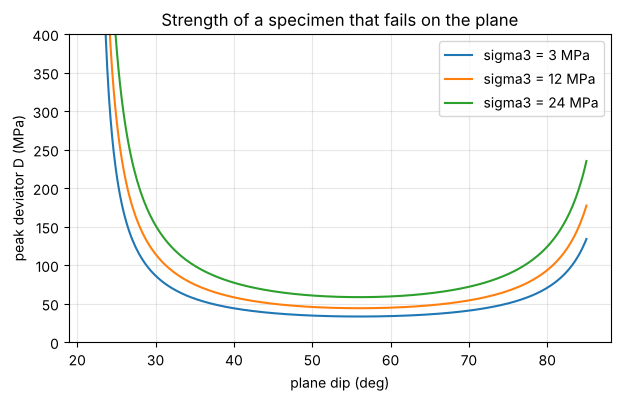

In [2]:
dips = np.linspace(5, 85, 400)
fig, ax = plt.subplots(figsize=(7, 4))
for s3 in (3, 12, 24):
    ax.plot(dips, jaeger_D(s3, dips, 10, 22), label=f"sigma3 = {s3} MPa")
ax.set_ylim(0, 400); ax.set_xlabel("plane dip (deg)"); ax.set_ylabel("peak deviator D (MPa)")
ax.set_title("Strength of a specimen that fails on the plane"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## The point on the Mohr diagram

Each test gives **one** point `(sn, tau)`. The next notebook fits a line through the points of many specimens.

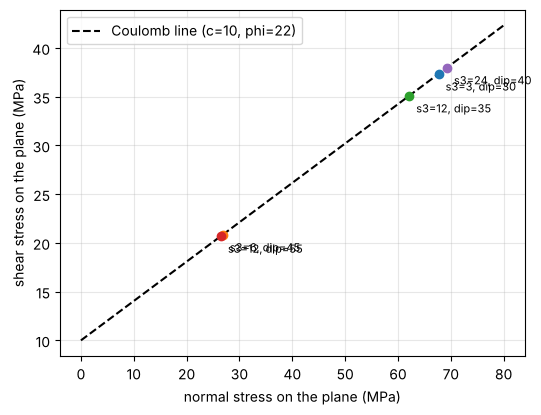

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5))
x = np.linspace(0, 80, 50)
ax.plot(x, c + x*np.tan(np.radians(phi)), "k--", label="Coulomb line (c=10, phi=22)")
for s3_, dip_ in [(3, 30), (6, 45), (12, 35), (12, 55), (24, 40)]:
    D_ = float(jaeger_D(s3_, dip_, c, phi)); a, b = sn_tau(s3_, D_, dip_)
    ax.plot(a, b, "o"); ax.annotate(f"s3={s3_}, dip={dip_}", (a, b), textcoords="offset points", xytext=(5, -12), fontsize=8)
ax.set_xlabel("normal stress on the plane (MPa)"); ax.set_ylabel("shear stress on the plane (MPa)"); ax.legend(); ax.grid(alpha=.3)
plt.show()

## Sensitivity: how much does D change when c changes by 1 MPa?

`dD/dc = 1 / (sin(theta) cos(theta) - cos^2(theta) tan(phi))`. For mid dips it is about 3, for shallow planes 6 to 9.
This is why a small error in `c` has a larger effect on the peak of a flat plane. (Below a dip equal to `phi` the plane cannot slide, and the formula has no meaning.)

In [4]:
for d_ in (30, 45, 60, 75):
    th = np.radians(d_); t = np.tan(np.radians(22))
    print(f"dip {d_:2d} deg:  dD/dc = {1/(np.sin(th)*np.cos(th) - np.cos(th)**2*t):5.1f}")

dip 30 deg:  dD/dc =   7.7
dip 45 deg:  dD/dc =   3.4
dip 60 deg:  dD/dc =   3.0
dip 75 deg:  dD/dc =   4.5
